In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score

# Data and features
train=pd.read_csv("MLProject2026/data/case1/train1.csv")
test=pd.read_csv("MLProject2026/data/case1/test1.csv")
for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]
    df["deltaP"]=df["outlet_pressure_bar"]-df["inlet_pressure_bar"]

X_train, y_train= train[["n","P","deltaP"]], train["Q"]
X_test, y_test= test[["n","P","deltaP"]], test["Q"]

In [2]:
all_cols = list(X_train.columns)
n_cols = len(all_cols)

all_subsets = [[]]
for col in all_cols:
    new_subsets = []
    for subset in all_subsets:
        new_subsets.append(subset + [col])
    all_subsets = all_subsets + new_subsets
all_subsets = all_subsets[1:]

In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=30)

results = []
for subset in all_subsets:
    scores = cross_val_score(LinearRegression(), X_train[subset], y_train,
                             cv=cv, scoring="neg_mean_squared_error")
    e = -scores
    results.append({"n_terms": len(subset), "features": tuple(subset),
                    "mse": e.mean(), "se": e.std(ddof=1) / np.sqrt(len(e))})
results = pd.DataFrame(results)
results.sort_values("mse")

,n_terms,features,mse,se
6,3,"(n, P, deltaP)",12.192435,0.797782
5,2,"(P, deltaP)",20.130007,0.689996
4,2,"(n, deltaP)",34.991711,1.238502
2,2,"(n, P)",88.123316,1.974420
1,1,"(P,)",100.152153,2.288870
0,1,"(n,)",132.518247,4.362363
3,1,"(deltaP,)",171.359433,7.318371


In [4]:
model=LinearRegression().fit(X_train,y_train)
y_pred=model.predict(X_test)

r2_score(y_test, y_pred)


0.9141984630856215

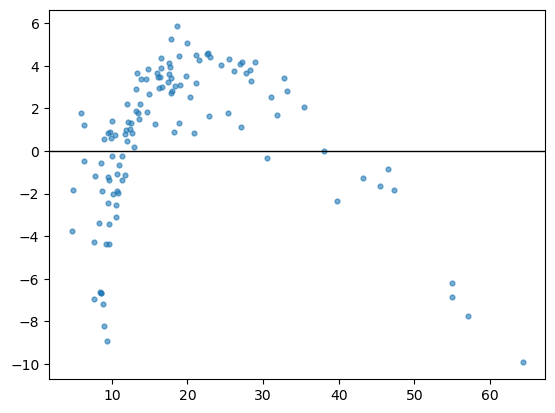

In [5]:
resid = y_test-y_pred
plt.scatter(y_pred, resid, s=12, alpha=0.6)
plt.axhline(0, color="k", lw=1)
plt.xlabel("")
plt.ylabel("")
plt.title("")
plt.show()

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score

# Data and features
train=pd.read_csv("MLProject2026/data/case1/train1.csv")
test=pd.read_csv("MLProject2026/data/case1/test1.csv")
for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q/n"] = df["flow_m3_h"]/df["n"]
    df["P/n^3"] = df["power_w"]/(df["n"]**3)
    df["deltaP/n^2"] = (df["outlet_pressure_bar"] - df["inlet_pressure_bar"]) / (df["n"]**2)

X_train, y_train= train[["n","P/n^3","deltaP/n^2"]], train["Q/n"]
X_test, y_test= test[["n","P/n^3","deltaP/n^2"]], test["Q/n"]

In [1]:
#Jeg forsøger lige med anden scalling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score

# Data and features
train=pd.read_csv("../data/case1/train1.csv")
test=pd.read_csv("../data/case1/test1.csv")
for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P**1/3"] = df["power_w"]**(1/3)
    df["deltaP**1/2"] = (df["outlet_pressure_bar"] - df["inlet_pressure_bar"]) **(1/2)

X_train, y_train= train[["n","P**1/3","deltaP**1/2"]], train["Q"]
X_test, y_test= test[["n","P**1/3","deltaP**1/2"]], test["Q"]

In [6]:
#samme som før bare med lineære termer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score

# Data and features
train=pd.read_csv("../data/case1/train1.csv")
test=pd.read_csv("../data/case1/test1.csv")
for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]
    df["P**1/3"] = df["power_w"]**(1/3)
    df["deltaP"] = (df["outlet_pressure_bar"] - df["inlet_pressure_bar"])
    df["deltaP**1/2"] = (df["outlet_pressure_bar"] - df["inlet_pressure_bar"]) **(1/2)

X_train, y_train= train[["n","P**1/3","deltaP**1/2", "P", "deltaP"]], train["Q"]
X_test, y_test= test[["n","P**1/3","deltaP**1/2", "P", "deltaP"]], test["Q"]

In [7]:
all_cols = list(X_train.columns)
n_cols = len(all_cols)

all_subsets = [[]]
for col in all_cols:
    new_subsets = []
    for subset in all_subsets:
        new_subsets.append(subset + [col])
    all_subsets = all_subsets + new_subsets
all_subsets = all_subsets[1:]

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=30)

results = []
for subset in all_subsets:
    scores = cross_val_score(LinearRegression(), X_train[subset], y_train,
                             cv=cv, scoring="neg_mean_squared_error")
    e = -scores
    results.append({"n_terms": len(subset), "features": tuple(subset),
                    "mse": e.mean(), "se": e.std(ddof=1) / np.sqrt(len(e))})
results = pd.DataFrame(results)
results.sort_values("mse")

,n_terms,features,mse,se
30,5,"(n, P**1/3, deltaP**1/2, P, deltaP)",1.465974,0.018969
22,4,"(n, P**1/3, deltaP**1/2, deltaP)",1.550561,0.049654
14,4,"(n, P**1/3, deltaP**1/2, P)",1.551770,0.026507
6,3,"(n, P**1/3, deltaP**1/2)",1.805669,0.075488
21,3,"(P**1/3, deltaP**1/2, deltaP)",1.870170,0.066943
29,4,"(P**1/3, deltaP**1/2, P, deltaP)",1.887305,0.073842
13,3,"(P**1/3, deltaP**1/2, P)",2.122122,0.065650
5,2,"(P**1/3, deltaP**1/2)",2.192888,0.069030
26,4,"(n, P**1/3, P, deltaP)",5.185346,0.273028
25,3,"(P**1/3, P, deltaP)",5.432781,0.256627


In [9]:
model=LinearRegression().fit(X_train,y_train)
y_pred=model.predict(X_test)
Q_pred = y_pred
r2_score(test["flow_m3_h"], Q_pred)

0.9915875507802424

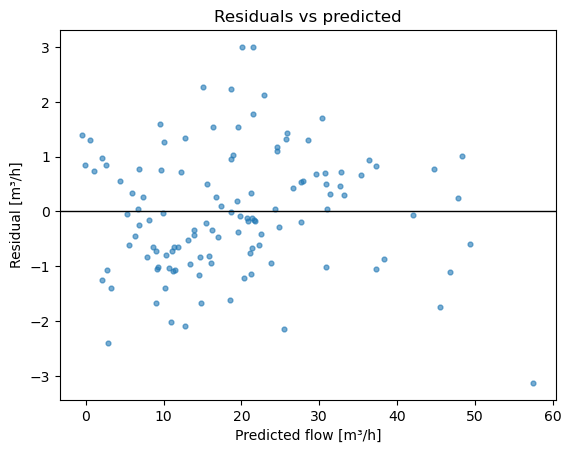

In [11]:
Q_true = test["flow_m3_h"]
Q_pred = y_pred
resid = Q_true - Q_pred

plt.scatter(Q_pred, resid, s=12, alpha=0.6)
plt.axhline(0, color="k", lw=1)
plt.xlabel("Predicted flow [m³/h]")
plt.ylabel("Residual [m³/h]")
plt.title("Residuals vs predicted")
plt.show()

In [11]:
from sklearn.tree import DecisionTreeRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=30)

results = []
for subset in all_subsets:
    model = DecisionTreeRegressor(max_depth=5, criterion="squared_error", random_state=0)
    scores = cross_val_score(model, X_train[subset], y_train,
                             cv=cv, scoring="neg_mean_squared_error")
    e = -scores
    results.append({"n_terms": len(subset), "features": tuple(subset),
                    "mse": e.mean(), "se": e.std(ddof=1) / np.sqrt(len(e))})
results = pd.DataFrame(results)
results.sort_values("mse")

,n_terms,features,mse,se
6,3,"(n, P/n^3, deltaP/n^2)",0.542846,0.116342
5,2,"(P/n^3, deltaP/n^2)",0.791369,0.126074
4,2,"(n, deltaP/n^2)",1.520788,0.247662
3,1,"(deltaP/n^2,)",1.523556,0.185293
2,2,"(n, P/n^3)",6.623186,0.712293
1,1,"(P/n^3,)",8.220174,0.930823
0,1,"(n,)",13.116712,0.286442


In [12]:
best_features = list(results.sort_values("mse").iloc[0]["features"])

model = DecisionTreeRegressor(max_depth=5, criterion="squared_error", random_state=0)
model.fit(X_train[best_features], y_train)

y_pred = model.predict(X_test[best_features])

# Back to flow units for evaluation
Q_pred = y_pred * test["n"]
print("Features:", best_features)
print("R² (Q):", r2_score(test["flow_m3_h"], Q_pred))

Features: ['n', 'P/n^3', 'deltaP/n^2']
R² (Q): 0.9856097625292891


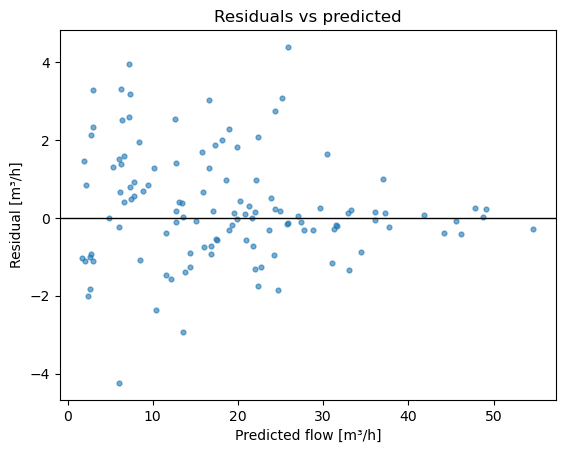

In [13]:
Q_true = test["flow_m3_h"]
resid = Q_true - Q_pred

plt.scatter(Q_pred, resid, s=12, alpha=0.6)
plt.axhline(0, color="k", lw=1)
plt.xlabel("Predicted flow [m³/h]")
plt.ylabel("Residual [m³/h]")
plt.title("Residuals vs predicted")
plt.show()